In [1]:
import numpy as np
from astroquery.vizier import Vizier
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord


In [14]:
#Datensätze Laden

v = Vizier(columns=["**"], row_limit=-1)     # v ist Anfrage Objekt mit row limit -1 damit nicht nur die standard ersten 50 einträge geladen werden sondern alle
v.VIZIER_SERVER = "vizier.cfa.harvard.edu"   # Server ändern das Strassbourg gehackt wurde
bosch2016 = v.get_catalogs("J/ApJ/831/134")[0]
print(bosch2016.colnames)
#Weitere interessante Cataloge
#J/ApJ/798/54  Graham 2015
#J/ApJ/811/91  Woo 2015
#J/ApJ/897/111 Zaw 2020

['recno', 'Name', 'f_Name', 'Dist', 'e_Dist', 'logBHMass', 'E_logBHMass', 'e_logBHMass', 'logsigma', 'e_logsigma', 'logLk', 'e_logLk', 'logRe', 'e_logRe', 'cov', 'C28', 'e_C28', 'logAGN', 'e_logAGN', 'Meth', 'Refs', 'SimbadName', 'NED', '_RA', '_DE']


In [15]:
#Benötigt Daten bereinigen

raw_mbh_bosch = np.array(bosch2016["logBHMass"], dtype=float)
raw_sigma_bosch = np.array(bosch2016["logsigma"], dtype=float)

mask= (~np.isnan(raw_mbh_bosch)) & (~np.isnan(raw_sigma_bosch)) & (raw_sigma_bosch > 0)  #Maske um Leere und Negative Werte zu filtern

sigma_bosch = raw_sigma_bosch[mask]   #von leeren und unrealistischen einträgen befreite Daten
mbh_bosch = raw_mbh_bosch[mask]

In [62]:
#Bootstrapping

def bootstrapping_mean(data, anzahl=5000):                           #data = die Daten die gebootstrapt werden sollen  n_boot = anzahl der simulierten neuverteilungen
  rng = np.random.default_rng(42069)                                 #rng mit festem Seed damit Resultat beim wiederaufruf des Notebooks gleichbleibt
  sims = np.empty(anzahl)                                            #leeres array in dem die simulierten Daten nach jedem durchlauf eingetragen werden 
  n = len(data)                                                      #Menge der Daten damit bei jeder simulation wieder identisch viele neu gezogen werden
  for i in range(anzahl):                                            #schleife die das gesamte sims array füllt 
    sample = rng.choice(data, size=n, replace=True)                  #neu generiertes sample aus der ziehung mit zurücklegen der ursprungs daten
    sims[i] = np.mean(sample)                                        #trägt für jedes generierte sample den median in das sims array ein
  konfidenz_low, konfidenz_high = np.percentile(sims, [2.5, 97.5])   #berechnet die grenzen für 95% Konfidenzintervall
  return np.mean(data), konfidenz_low, konfidenz_high, sims


Mittelwert log(M_BH): 7.62 | 95%-Konfidenzintervall: [7.42, 7.81]


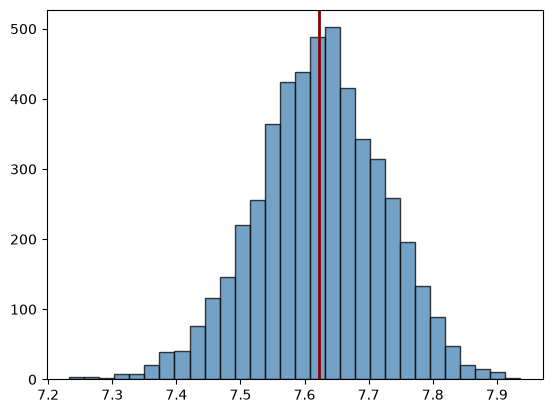

In [68]:
med_m, low_m, high_m, mbh_sims = bootstrapping_mean(mbh_bosch)
print(f"Mittelwert log(M_BH): {med_m:.2f} | 95%-Konfidenzintervall: [{low_m:.2f}, {high_m:.2f}]") #:.2f lässt nur 2 kommastellen ausgeben
plt.hist(
    mbh_sims,
    bins=30,
    color="steelblue",
    edgecolor="black",
    alpha=0.75,
    label="Bootstrap-Mediane",
)
plt.axvline(
    med_m, color="darkred", linewidth=2, label=f"Original-Median = {med_m:.2f}"
)
plt.show()